<a href="https://colab.research.google.com/github/tuankhoin/CO3133-Deep-Learning/blob/main/Week_8_Programming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ho Chi Minh University of Technology (HCMUT)

CO3133 - Deep Learning and Its Applications

# Week 8 - Deep Learning Code Literacy

### Reading, Writing, Debugging, and Running Deep-Learning Code

This week is practical. And yes, **it is examinable**

The goal is not to memorize one framework API. The goal is to be able to:

- read unfamiliar deep-learning code;
- reason about tensor shapes, dtype, device, and gradients;
- build and train small PyTorch models correctly;
- recognize common implementation mistakes;
- connect code patterns back to CNNs, RNNs, Transformers, segmentation, and detection;
- use external repositories without treating them as black boxes.

All demonstrations use small synthetic data so the notebook can be run top-to-bottom in Colab without downloading a dataset.

___
# 0. Exam Structure
___

- 90 minutes
- 60 MCQ Questions
- Equipment: 1x handwritten A4 + calculator


<img src="https://raw.githubusercontent.com/tuankhoin/CO3057-Computer-Vision/refs/heads/main/assets/colab.png" height=300/>

---
# 1. Environment and Colab Setup
---

## Do Not Reinstall PyTorch Blindly

Google Colab normally includes PyTorch already.

Before installing anything, inspect:

- Python version
- PyTorch version
- CUDA version used by PyTorch
- whether a GPU is visible

Unnecessary upgrades can create dependency conflicts.

In [ ]:
# Environment Verification
# Import fundamental system, platform, and standard utility packages
import sys, platform, random, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Safely attempt to import seaborn for matrix and curve visualizations
try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False

# Import core PyTorch libraries for deep learning models
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Output diagnostic environment information
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("Seaborn available:", HAS_SEABORN)

Python: 3.13.16
PyTorch: 2.14.1+cu130
PyTorch CUDA build: 13.0
CUDA available: True
Seaborn available: True


## Device Selection

Use one variable:

```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
```

Then move both model and tensors:

```python
model = model.to(device)
x = x.to(device)
y = y.to(device)
```

Avoid scattering hard-coded `.cuda()` calls throughout a project.

In [ ]:
# Unified Device Selection and Seed Standardization
# Establish a single target hardware device (CUDA GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

# Set random seeds across Python, NumPy, and PyTorch for exact run-to-run reproducibility
SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Selected device: cuda


## Installing the Right Version

When installation is actually needed, think in terms of compatibility:

$$
\text{Python}
\leftrightarrow
\text{PyTorch build}
\leftrightarrow
\text{CUDA runtime}
\leftrightarrow
\text{third-party extension}.
$$

Prefer a fresh environment and pin working versions using files such as:

```text
requirements.txt
environment.yml
pyproject.toml
```

Useful diagnostic commands:

In [ ]:
# Verify active python runtime version in Colab
!python --version

Python 3.13.16


In [ ]:
# Show exact installation metadata, versions, and dependencies for PyTorch ecosystems
!pip show torch torchvision torchaudio

Name: torch
Version: 2.14.1+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision
---
Name: torchvision
Version: 0.29.1+cu130
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Core Team
Author-email: soumith@pytorch.org
License: BSD
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, pillow, torch
Required-by: fast

In [ ]:
# Query the system driver for GPU status, VRAM usage, and active CUDA environments
!nvidia-smi

Tue Nov 10 07:03:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Snapshot and write out all environment package versions for pipeline reproducibility
!pip freeze > requirements.txt

---
# 2. Python for Reporting
---

These tools help inspect data and report experiments.

They are not the model itself.

## NumPy

NumPy and PyTorch share the ideas of:

- shape;
- indexing;
- broadcasting;
- vectorized computation.

In [ ]:
# NumPy Operations Demonstration
# Initialize a 1D sequence and reshape to a 2D matrix (3 rows, 4 columns)
a = np.arange(12).reshape(3, 4)

print(a)
print("shape:", a.shape)
print("row 1:", a[1])            # Extracting the second row (index 1)
print("column 2:", a[:, 2])       # Extracting all elements of the third column (index 2)
print("column means:", a.mean(axis=0))  # Calculate average values collapsing down axis 0 (columns)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4)
row 1: [4 5 6 7]
column 2: [ 2  6 10]
column means: [4. 5. 6. 7.]


## pandas

Use DataFrames for:

- experiment logs;
- per-class metrics;
- metadata;
- CSV input/output.

In [ ]:
# pandas Experiment Logs
# Store metrics across training steps inside a DataFrame
history_df = pd.DataFrame({
    "epoch": [1, 2, 3, 4],
    "train_loss": [0.92, 0.71, 0.55, 0.43],
    "val_loss": [0.95, 0.76, 0.62, 0.58],
    "val_accuracy": [0.60, 0.69, 0.75, 0.77],
})

display(history_df)
# Dynamically retrieve and display the row associated with the best accuracy
display(history_df.loc[[history_df["val_accuracy"].idxmax()]])

,epoch,train_loss,val_loss,val_accuracy
0,1,0.92,0.95,0.60
1,2,0.71,0.76,0.69
2,3,0.55,0.62,0.75
3,4,0.43,0.58,0.77


,epoch,train_loss,val_loss,val_accuracy
3,4,0.43,0.58,0.77


## Matplotlib and Seaborn

Useful plots include:

- train/validation curves;
- confusion matrices;
- class-frequency plots;
- qualitative predictions.

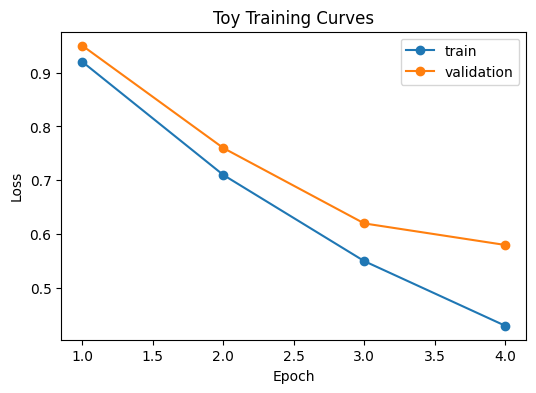

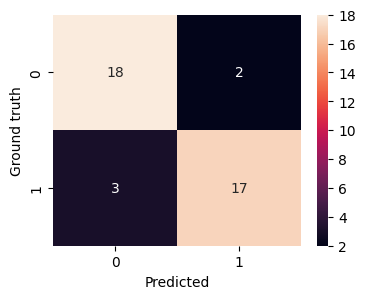

In [ ]:
# Visualizing Loss Curves & Confusion Matrices
plt.figure(figsize=(6,4))
# Plot loss trends over epochs
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Toy Training Curves")
plt.legend()
plt.show()

# Generate a classification evaluation matrix using Seaborn if available
if HAS_SEABORN:
    cm = np.array([[18, 2], [3, 17]])
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d")
    plt.xlabel("Predicted")
    plt.ylabel("Ground truth")
    plt.show()

---
# 3. PyTorch Tensor Literacy
---

## Shape, dtype, Device

Inspect tensors with:

```python
x.shape
x.dtype
x.device
x.requires_grad
```

A tensor operation can be mathematically correct but still fail because dtype or device is wrong.

In [ ]:
# Shape, dtype, and Device Tracking
# Create a standard input batch (32 samples, 8 features)
x = torch.randn(32, 8)

# Create integer class targets for multiclass/binary classification (values 0 or 1)
y_class = torch.randint(0, 2, (32,))

# Convert class targets to float and unsqueeze to match BCEWithLogitsLoss expected shape (32, 1)
y_float = y_class.float().unsqueeze(1)

# Print diagnostic information answering the 'Five Questions'
print("x:", x.shape, x.dtype, x.device, x.requires_grad)
print("class target:", y_class.shape, y_class.dtype)
print("binary float target:", y_float.shape, y_float.dtype)

x: torch.Size([32, 8]) torch.float32 cpu False
class target: torch.Size([32]) torch.int64
binary float target: torch.Size([32, 1]) torch.float32


## `reshape`, `view`, `flatten`

A feature map:
$
(B,C,H,W)
$
can be flattened to:
$
(B,CHW).
$

In [ ]:
# Reshaping and Flattening Feature Maps
# Simulating a convolutional feature map with shape: (Batch, Channels, Height, Width)
feat = torch.randn(4, 8, 5, 5)

# Method A: Reshape keeping batch size (dim 0) and flattening everything else (-1)
flat1 = feat.reshape(feat.size(0), -1)

# Method B: Use torch.flatten starting at dim 1 (preserving batch size at dim 0)
flat2 = torch.flatten(feat, start_dim=1)

print(feat.shape, flat1.shape, flat2.shape)
print("same:", torch.allclose(flat1, flat2))  # Verifying both methods yield identical tensors

torch.Size([4, 8, 5, 5]) torch.Size([4, 200]) torch.Size([4, 200])
same: True


## `transpose` vs `permute`

`transpose(a,b)` swaps two dimensions.

`permute(...)` defines the full new order.

Example:

$$
(B,T,D)\rightarrow(B,D,T).
$$

In [ ]:
# Swapping Dimensions: transpose vs permute
# Simulating a sequence batch with shape: (Batch, Time, Dimension)
seq = torch.randn(2, 5, 7)

print("original :", seq.shape)
# transpose(1, 2) specifically swaps the Time (1) and Dimension (2) axes
print("transpose:", seq.transpose(1, 2).shape)
# permute(...) allows us to explicitly define the entire new layout order
print("permute  :", seq.permute(0, 2, 1).shape)

original : torch.Size([2, 5, 7])
transpose: torch.Size([2, 7, 5])
permute  : torch.Size([2, 7, 5])


## Broadcasting

If:
$\boxed{
X\in\mathbb{R}^{B\times D}
}$,
$\boxed{
b\in\mathbb{R}^{D}},
$

then
$\boxed{
X+b
}$
adds the same bias to each row.

In [ ]:
# Broadcasting Rules
# 2D target matrix (3 rows, 4 columns)
X = torch.arange(12, dtype=torch.float32).reshape(3,4)
print(X)
# 1D vector (4 elements) matching the last dimension size of X
bias = torch.tensor([10., 20., 30., 40.])
# PyTorch stretches bias automatically along the rows to match dimensions during addition
print(X + bias)

tensor([[10., 21., 32., 43.],
        [14., 25., 36., 47.],
        [18., 29., 40., 51.]])


## `clone()` vs `detach()`

### `clone()`
Copies values into a new tensor.

Useful when later in-place assignments would destroy values that are still needed later.

### `detach()`
Disconnects a tensor from autograd.

Useful when saving **predictions for reporting/inference**.

In [ ]:
# Safe Manipulation via Clone
boxes = torch.tensor([[10., 20., 30., 40.]])
W = 100.

# Create an independent copy to prevent editing the original tensor values in-place
safe = boxes.clone()
x1_old = safe[:,0].clone()
x2_old = safe[:,2].clone()
safe[:,0] = W - x2_old
safe[:,2] = W - x1_old

print("original:", boxes)
print("flipped :", safe)

original: tensor([[10., 20., 30., 40.]])
flipped : tensor([[70., 20., 90., 40.]])


## `cpu()` and `item()`

Use:

```python
tensor.detach().cpu()
```

to save a tensor for reporting.

Use:

```python
scalar_tensor.item()
```

to obtain one Python scalar.

In [ ]:
# Safe Detachment and Scalar Retrieval
# Simulate model predictions (logits) tracking gradients
logits = torch.randn(6, 3, requires_grad=True)
labels = torch.randint(0, 3, (6,))

# Sum correct predictions and extract the raw Python integer scalar using .item()
correct = (logits.argmax(1) == labels).sum().item()

print(correct, type(correct))
# Safely copy predictions to CPU and detach from the autograd graph for reporting
print(logits.argmax(1).detach().cpu())

3 <class 'int'>
tensor([2, 2, 1, 2, 2, 0])


---
# 4. Building Models with PyTorch
---

## `nn.Module`

Define components in `__init__` and computation in `forward`.

In [ ]:
# Defining a basic Multi-Layer Perceptron (MLP) block
class TinyMLP(nn.Module):
    def __init__(self, in_features=8, hidden=16, num_classes=2):
        super().__init__()
        # Sequential container stacking a Linear layer, Activation, Dropout, and final projection
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        # Define forward propagation through the Sequential block
        return self.net(x)

model_demo = TinyMLP()
dummy = torch.randn(5,8)

print(model_demo)
print("input :", dummy.shape)    # Standard batch layout (B, D)
print("output:", model_demo(dummy).shape)  # Logits mapping to (B, C)

TinyMLP(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=16, out_features=2, bias=True)
  )
)
input : torch.Size([5, 8])
output: torch.Size([5, 2])


## Parameter Count

Trainable parameter count:
$
\sum_{p\in\theta}\operatorname{numel}(p).
$

In [ ]:
# Calculating and distinguishing overall vs trainable parameters using parameter.numel()
total = sum(p.numel() for p in model_demo.parameters())
trainable = sum(p.numel() for p in model_demo.parameters() if p.requires_grad)

print("total:", total)
print("trainable:", trainable)

total: 178
trainable: 178


## Common Components

You should recognize:

```python
nn.Linear
nn.Conv2d
nn.BatchNorm2d
nn.LayerNorm
nn.ReLU
nn.GELU
nn.Dropout
nn.MaxPool2d
nn.Embedding
nn.LSTM
nn.MultiheadAttention
```

In [ ]:
# Instantiating Common Structural Network Layers
blocks = {
    "Linear": nn.Linear(16, 32),
    "Conv2d": nn.Conv2d(3, 16, 3, padding=1),
    "BatchNorm2d": nn.BatchNorm2d(16),
    "LayerNorm": nn.LayerNorm(32),
    "Dropout": nn.Dropout(0.2),
    "Embedding": nn.Embedding(100, 32),
    "LSTM": nn.LSTM(32, 64, batch_first=True),
    "MultiheadAttention": nn.MultiheadAttention(32, 4, batch_first=True),
}
# Loop and print metadata to verify input and output structures
for name, layer in blocks.items():
    print(f"{name:20s} -> {layer}")

Linear               -> Linear(in_features=16, out_features=32, bias=True)
Conv2d               -> Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
BatchNorm2d          -> BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
LayerNorm            -> LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
Dropout              -> Dropout(p=0.2, inplace=False)
Embedding            -> Embedding(100, 32)
LSTM                 -> LSTM(32, 64, batch_first=True)
MultiheadAttention   -> MultiheadAttention(
  (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
)


---
# 5. Training, Validation, Testing
---

We use a small synthetic dataset so the entire notebook remains self-contained.

In [ ]:
# Creating Synthetic Dataset Splits
g = torch.Generator().manual_seed(SEED)

# Generate sample features and target boundaries
X_all = torch.randn(600, 8, generator=g)
true_w = torch.tensor([1.2, -0.8, 0.6, 0.0, 0.5, -1.0, 0.3, 0.7])
score = X_all @ true_w + 0.25*torch.randn(600, generator=g)
y_all = (score > 0).long()  # Binary classification targets (0 or 1)

# Split into distinct Train (400), Validation (100), and Test (100) sets
train_ds = TensorDataset(X_all[:400], y_all[:400])
val_ds = TensorDataset(X_all[400:500], y_all[400:500])
test_ds = TensorDataset(X_all[500:], y_all[500:])

# Configure PyTorch DataLoaders (shuffling active ONLY on training data)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print(len(train_ds), len(val_ds), len(test_ds))

400 100 100


## Standard Training Step

Canonical order:

```python
optimizer.zero_grad()
logits = model(x)
loss = criterion(logits, y)
loss.backward()
optimizer.step()
```

PyTorch accumulates gradients unless they are cleared.

In [ ]:
# Initializing Model, Optimizer, and Learning Rate Scheduler
model = TinyMLP(8, 16, 2).to(device)  # Port model parameters to selected target hardware
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)

num_epochs = 3
total_steps = num_epochs * len(train_loader)
# Establish a decaying cosine schedule keyed to exact training update iterations
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=total_steps
)

print("planned optimizer steps:", total_steps)

planned optimizer steps: 39


## Correct Epoch Loss Averaging

If batch sizes differ, average by **number of samples**:

$$
\frac{
\sum_b \mathcal{L}_bN_b
}{
\sum_b N_b
}.
$$

In [ ]:
# Standard training epoch with sample-weighted loss accumulation
def train_one_epoch(model, loader, criterion, optimizer, scheduler, device):
    model.train()  # Explicitly set the model to training mode (activates Dropout/BatchNorm)

    loss_sum = 0.0
    correct = 0
    n_samples = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)  # Safely move input batch to target hardware device

        optimizer.zero_grad(set_to_none=True)  # Reset gradients to None for speed improvement
        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()  # Backpropagate gradients
        optimizer.step()  # Adjust model weights
        scheduler.step()  # Step learning rate scheduler per-iteration

        # Calculate sample-weighted metric summaries
        bs = y.size(0)
        loss_sum += loss.item() * bs
        correct += (logits.argmax(1) == y).sum().item()
        n_samples += bs

    return {
        "loss": loss_sum / n_samples,
        "accuracy": correct / n_samples,
    }

## Evaluation

`model.eval()` changes Dropout/BatchNorm behavior.

It does **not** disable autograd.

For pure evaluation, combine evaluation mode with:

```python
torch.inference_mode()
```

or `torch.no_grad()`.

In [ ]:
# Evaluation loop running under Inference Mode to avoid building the computation graph
@torch.inference_mode()
def evaluate(model, loader, criterion, device):
    model.eval()  # Explicitly switch off dropouts and batch-normalization tracking

    loss_sum = 0.0
    correct = 0
    n_samples = 0
    all_pred, all_true = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        # Sample-weighted aggregation
        bs = y.size(0)
        loss_sum += loss.item() * bs
        correct += (logits.argmax(1) == y).sum().item()
        n_samples += bs

        # Accumulate metrics detached on CPU to prevent memory bloat
        all_pred.append(logits.argmax(1).cpu())
        all_true.append(y.cpu())

    return {
        "loss": loss_sum / n_samples,
        "accuracy": correct / n_samples,
        "pred": torch.cat(all_pred),
        "true": torch.cat(all_true),
    }

## Validation Selects the Model; Test Estimates Final Performance

Use validation for:

- checkpoint selection;
- hyperparameters;
- threshold tuning.

Use test only after the model is selected.

In [ ]:
# Custom Training and Model Checkpointing Loop
best_val_acc = -float("inf")
best_state = None
history = []

for epoch in range(1, num_epochs+1):
    # Run full training steps
    tr = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, device)
    # Run full evaluation steps
    va = evaluate(model, val_loader, criterion, device)

    history.append({
        "epoch": epoch,
        "train_loss": tr["loss"],
        "train_acc": tr["accuracy"],
        "val_loss": va["loss"],
        "val_acc": va["accuracy"],
    })

    # Checkpoint model parameters if current validation accuracy improves
    if va["accuracy"] > best_val_acc:
        best_val_acc = va["accuracy"]
        best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

history = pd.DataFrame(history)
display(history)

,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.625199,0.7125,0.585959,0.77
1,2,0.576473,0.7825,0.550794,0.82
2,3,0.546871,0.8025,0.544276,0.83


In [ ]:
# Model Load and Final Performance Evaluation
# Reload the state dictionary corresponding to the highest validation performance
model.load_state_dict(best_state)
model.to(device)

# Run model evaluation loop on hold-out testing sequence
test_metrics = evaluate(model, test_loader, criterion, device)

print("test loss    :", round(test_metrics["loss"], 4))
print("test accuracy:", round(test_metrics["accuracy"], 4))

test loss    : 0.5589
test accuracy: 0.83


[[45  9]
 [ 8 38]]


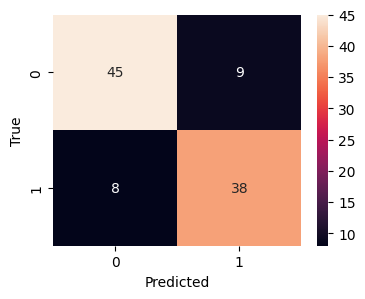

In [ ]:
# Calculating and Visualizing Validation Metrics
y_true = test_metrics["true"].numpy()
y_pred = test_metrics["pred"].numpy()

# Instantiate a 2x2 multi-class confusion matrix
cm = np.zeros((2, 2), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

print(cm)

# Render confusion matrix plot using Seaborn
if HAS_SEABORN:
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

---
# 6. Losses, Optimizers, Schedulers, Metrics
---

## Match Task → Output → Target → Loss

| Task | Model output | Target | Typical loss |
|---|---|---|---|
| Binary, one logit | `(N,1)` or `(N,)` logits | float, same shape | `BCEWithLogitsLoss` |
| Multiclass | `(N,C)` logits | integer `(N,)` | `CrossEntropyLoss` |
| Regression | float values | float values | MSE / MAE |
| Token classification | `(B,L,C)` | integer `(B,L)` | CE with ignored positions |
| Semantic segmentation | `(B,C,H,W)` | integer `(B,H,W)` | CE / overlap loss |

## Binary Classification

One raw logit per sample → `BCEWithLogitsLoss`.

Target must be floating point and shape-compatible.

In [ ]:
# Binary Classification: Logits and BCEWithLogitsLoss
# Unnormalized raw model output (logits) for single-class prediction
binary_logits = torch.tensor([[1.2], [-0.4], [0.8]])
# Floating-point targets matching the exact shape of the logits
binary_target = torch.tensor([[1.0], [0.0], [1.0]])

loss = nn.BCEWithLogitsLoss()(binary_logits, binary_target)
print(binary_logits.shape, binary_target.shape, loss.item())

torch.Size([3, 1]) torch.Size([3, 1]) 0.3824661076068878


## Multiclass Classification

For $C$ mutually exclusive classes:

```python
logits: (N,C), float
target: (N,), integer class indices
```

Use `CrossEntropyLoss`.

In [ ]:
# Multiclass Classification with CrossEntropyLoss
# Model output logits for C=4 mutually exclusive classes
multi_logits = torch.randn(5, 4)
# Multiclass targets must be integer class indices (torch.long)
multi_target = torch.tensor([0, 3, 1, 2, 1], dtype=torch.long)

loss = nn.CrossEntropyLoss()(multi_logits, multi_target)
print(multi_logits.shape, multi_target.shape, multi_target.dtype, loss.item())

torch.Size([5, 4]) torch.Size([5]) torch.int64 1.2233049869537354


## Token Classification and Ignored Positions

Padding/special positions can use:

```python
-100
```

and `CrossEntropyLoss(ignore_index=-100)`.

In [ ]:
B,L,C = 2,5,3
token_logits = torch.randn(B,L,C)
token_target = torch.tensor([
    [0,1,2,-100,-100],
    [1,1,0,2,-100],
])

loss = F.cross_entropy(
    token_logits.reshape(-1,C),
    token_target.reshape(-1),
    ignore_index=-100,
)
print(loss.item())

1.5941307544708252


## Regression: MSE vs MAE

MSE gives large residuals disproportionately more influence.

MAE grows linearly with residual magnitude.

In [ ]:
# Comparative Regression Losses: Mean Squared Error vs Mean Absolute Error
pred = torch.tensor([2., 2., 10.])
target = torch.tensor([1., 1., 1.])

# MSE computes squared residuals, punishing large outliers heavily
print("MSE:", F.mse_loss(pred, target).item())
# MAE computes absolute residuals, scaling linearly
print("MAE:", F.l1_loss(pred, target).item())

MSE: 27.66666603088379
MAE: 3.6666667461395264


## Semantic Segmentation

Common multiclass contract:

```python
logits: (B,C,H,W)
target: (B,H,W), dtype=torch.long
```

In [ ]:
# Semantic Segmentation Interface
# Logits are of shape (B, C, H, W) mapping class predictions per-pixel
seg_logits = torch.randn(2, 4, 16, 16)
# Target contains spatial map with correct integer label assignments (B, H, W)
seg_target = torch.randint(0, 4, (2, 16, 16))

print(F.cross_entropy(seg_logits, seg_target).item())

1.7435203790664673


## Separate Optimizers for Separate Networks

If two networks are updated independently, give each one its own optimizer.

A classic example is GAN generator/discriminator training.

In [ ]:
# Setting Up Independent Optimizers for Dual Subnetworks
G = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 4))
D = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 1))

# Creating distinct optimization targets for separate operational phases (e.g. GAN training)
opt_G = torch.optim.Adam(G.parameters(), lr=1e-3)
opt_D = torch.optim.Adam(D.parameters(), lr=1e-3)

print(len(opt_G.param_groups), len(opt_D.param_groups))

1 1


## Scheduler Step Units

Always ask:

> What does one scheduler `step()` mean?

If the schedule is specified in optimizer-update units, step it after optimizer updates.

If it is epoch-based, step it per epoch.

In [ ]:
# Step-Based Learning Rate Decays
toy_param = nn.Parameter(torch.tensor(1.0))
toy_opt = torch.optim.SGD([toy_param], lr=0.1)
toy_sched = torch.optim.lr_scheduler.CosineAnnealingLR(toy_opt, T_max=5)

# Iteratively decay and update learning rate across individual optimization steps
for step in range(5):
    toy_opt.zero_grad()
    loss = toy_param.square()
    loss.backward()
    toy_opt.step()
    toy_sched.step()  # Decay triggers explicitly post parameter step
    print(step+1, toy_opt.param_groups[0]["lr"])

1 0.09045084971874738
2 0.06545084971874737
3 0.03454915028125263
4 0.009549150281252633
5 0.0


## L2 Regularization

An explicit penalty is:

$$
\mathcal{L}_{total}
=
\mathcal{L}_{task}
+
\lambda\sum_p\|p\|_2^2.
$$

Its gradient adds a term proportional to each parameter, discouraging large weights.

In practice, `weight_decay` is commonly used.

---
# 7. Autograd, Model Modes, and Debugging
---

## `train()` vs `eval()` vs Gradient Tracking

`model.train()` / `model.eval()` affect module behavior such as:

- Dropout;
- BatchNorm.

They do not switch autograd off.

Use `torch.no_grad()` or `torch.inference_mode()` for evaluation without graph construction.

In [ ]:
# Contrastive Operational Modes: Train vs Eval
drop = nn.Dropout(p=0.5)
x = torch.ones(10)

# During training, elements are randomly zeroed out and scaled up
drop.train()
train_out = drop(x)

# During evaluation, dropout becomes an identity mapping to ensure static outputs
drop.eval()
eval_out = drop(x)

print("train:", train_out)
print("eval :", eval_out)

train: tensor([2., 0., 0., 2., 2., 0., 2., 2., 2., 0.])
eval : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## Saving Raw Logits Can Retain the Graph

During training:

```python
saved.append(logits)
```

can keep computation graphs alive.

For reporting:

```python
saved.append(logits.detach().cpu())
```

In [ ]:
# Autograd Detachment mechanics
tiny = nn.Linear(4, 2)
x = torch.randn(3, 4, requires_grad=True)
logits = tiny(x)

# Logits hold references to their respective backward projection operations
print("raw grad_fn:", logits.grad_fn)

# Calling detach() copies values, turning off autograd and isolating parameters safely
safe = logits.detach().cpu()
print("safe grad_fn:", safe.grad_fn)
print("safe requires_grad:", safe.requires_grad)

raw grad_fn: <AddmmBackward0 object at 0x7d679314f640>
safe grad_fn: None
safe requires_grad: False


## Device Mismatch

Create helper tensors directly on the correct device:

```python
target = torch.arange(B, device=features.device)
```

In [ ]:
# Device Coherence
# Automatically allocate a brand new helper tensor matching an active reference's target hardware device
v = torch.randn(4, 8, device=device)
target = torch.arange(v.size(0), device=v.device)

print(v.device, target.device)

cuda:0 cuda:0


## Prevent Data Leakage

Fit preprocessing using training data only.

This includes:

- normalization statistics;
- vocabulary;
- feature selection;
- imputation;
- thresholds.

Validation/test information should not influence fitted preprocessing.

In [ ]:
# Standardizing Preprocessing Features to Avoid Data Leakage
train_values = torch.tensor([1., 2., 3., 4.])
val_values = torch.tensor([100., 101.])

# Compute normalization profiles ONLY from the active training collection
mu = train_values.mean()
sigma = train_values.std()

# Apply established stats onto validation sequences without leakage
print((val_values-mu)/sigma)

tensor([75.5232, 76.2978])


## Oversampling Is a Training Decision

Oversampling intentionally changes the training distribution.

Validation should normally preserve the target evaluation distribution.

Do not reuse the training sampler automatically for validation.

---
# 8. Code Patterns from Previous Lectures
---

The aim is recognition, not reteaching all theory.

## MLP Pattern

$$
(B,D)\rightarrow Linear\rightarrow Activation\rightarrow Linear\rightarrow(B,C).
$$

In [ ]:
# MLP Sequence Verification
mlp = nn.Sequential(nn.Linear(8, 32), nn.ReLU(), nn.Linear(32, 3))
x = torch.randn(5, 8)
# Verify structural shape transformations from features to class boundaries
print(x.shape, "->", mlp(x).shape)

torch.Size([5, 8]) -> torch.Size([5, 3])


## CNN Pattern

`Conv2d` expects:

$$
(B,C,H,W).
$$

`in_channels` must match the input.

In [ ]:
# CNN Dimensional Standard
gray = torch.randn(4, 1, 28, 28)  # Expected batch shape: (B, C, H, W)
conv = nn.Conv2d(1, 16, 3, padding=1)
# Inspect 2D dimensional updates across spatial convolutions
print(gray.shape, "->", conv(gray).shape)

torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16, 28, 28])


## RNN / LSTM Pattern

With `batch_first=True`:

$$
(B,T,D)
$$

is the usual input layout.

In [ ]:
# Recurrent Sequence Layouts
rnn_x = torch.randn(3, 7, 16)  # Inputs represent (Batch, Seq_Len, Hidden)
lstm = nn.LSTM(16, 32, batch_first=True)  # Specify batch_first to conform with inputs

# Extract sequential representations along with last hidden state context
seq_out, (h_n, c_n) = lstm(rnn_x)

print("input :", rnn_x.shape)
print("output:", seq_out.shape)
print("h_n   :", h_n.shape)
print("c_n   :", c_n.shape)

input : torch.Size([3, 7, 16])
output: torch.Size([3, 7, 32])
h_n   : torch.Size([1, 3, 32])
c_n   : torch.Size([1, 3, 32])


## Transformer Q/K/V and Head Reshaping

Input:

$$
X\in\mathbb{R}^{B\times L\times d_{model}}.
$$

For $H$ heads:

$$
d_h=d_{model}/H.
$$

Split into:

$$
(B,H,L,d_h).
$$

In [ ]:
# Transformer sequence & multi-head projection splitting logic
B,L,d_model,H = 2,6,32,4
d_head = d_model//H

x = torch.randn(B,L,d_model)
Wq = nn.Linear(d_model,d_model,bias=False)
Wk = nn.Linear(d_model,d_model,bias=False)
Wv = nn.Linear(d_model,d_model,bias=False)

# Split sequence dimension into multiple parallel attention heads
def split_heads(t):
    # Reshape from (B, L, d_model) to (B, L, H, d_head) and swap to (B, H, L, d_head)
    return t.view(B, L, H, d_head).transpose(1, 2)

q = split_heads(Wq(x))
k = split_heads(Wk(x))
v = split_heads(Wv(x))

# Compute Scaled Dot-Product Attention: QK^T / sqrt(d_k)
scores = q @ k.transpose(-2, -1) / (d_head**0.5)
attn = scores.softmax(dim=-1)
context = attn @ v  # Weighted sum representation (B, H, L, d_head)

print("q:", q.shape)
print("attention:", attn.shape)
print("context:", context.shape)

q: torch.Size([2, 4, 6, 8])
attention: torch.Size([2, 4, 6, 6])
context: torch.Size([2, 4, 6, 8])


## Causal Mask

Autoregressive attention blocks future positions:

$$
j>i.
$$

In [ ]:
# Autoregressive Causal Attention Masking
L = 5
# Generate an upper-triangular boolean mask matrix
causal_mask = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)

scores = torch.zeros(1, 1, L, L)
# Replace future attention positions with negative infinity
masked = scores.masked_fill(causal_mask, float("-inf"))
attn = masked.softmax(dim=-1)  # Softmax nullifies masked futures to zero probabilities

print(causal_mask.int())
print(attn[0, 0])

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


## Attention Dropout

Dropout may be applied after softmax.

During training, retained values are rescaled, so one sampled row does not need to sum to exactly 1.

In [ ]:
# Evaluating Post-Attention Dropout Scaling
torch.manual_seed(0)
weights = torch.softmax(torch.tensor([[1., 2., 3., 4.]]), dim=-1)
drop_attn = nn.Dropout(0.5)
drop_attn.train()  # Explicit training mode to compute dropping and compensation factor
dropped = drop_attn(weights)

print(weights, weights.sum().item())
# Note that remaining values scale up, which might not sum back to 1.0
print(dropped, dropped.sum().item())

tensor([[0.0321, 0.0871, 0.2369, 0.6439]]) 1.0
tensor([[0.0000, 0.0000, 0.4738, 0.0000]]) 0.47376567125320435


## Grouped-Query Attention

If there are 16 query heads and 4 K/V heads, each K/V head can serve 4 query heads.

A simple conceptual implementation repeats K/V heads to match query-head count.

In [ ]:
# Grouped-Query Attention Setup
B, Hq, Hkv, L, Dh = 2, 16, 4, 5, 8

q = torch.randn(B, Hq, L, Dh)
k_small = torch.randn(B, Hkv, L, Dh)
v_small = torch.randn(B, Hkv, L, Dh)

# Compute group ratios and repeat K/V representations to resolve head alignment
group = Hq // Hkv
k = k_small.repeat_interleave(group, dim=1)
v = v_small.repeat_interleave(group, dim=1)

print(q.shape, k_small.shape, k.shape)

torch.Size([2, 16, 5, 8]) torch.Size([2, 4, 5, 8]) torch.Size([2, 16, 5, 8])


## KV Cache

Cached keys/values grow along the **sequence dimension**.

If cached decoding disagrees with full-prefix decoding, inspect:

- position indices;
- concatenation axis;
- cache length;
- causal mask.

In [ ]:
# Expanding the Key-Value Cache Sequence
k_cache = torch.randn(1, 4, 3, 8)  # Historical context (Batch, Heads, Seq_Len, Dim)
k_new = torch.randn(1, 4, 1, 8)    # New incoming token projection
# Concatenate along the sequence axis (dimension 2) to maintain history context
k_cache = torch.cat([k_cache, k_new], dim=2)
print(k_cache.shape)

torch.Size([1, 4, 4, 8])


## Segmentation: Upsampling + Skip Fusion

A common decoder pattern:

1. upsample coarse feature;
2. fuse with finer feature;
3. refine.

In [ ]:
# Segmentation Upsampling & Feature Skip-Connection Fusion
coarse = torch.randn(2, 64, 16, 16)
skip = torch.randn(2, 32, 32, 32)

# Upscale high-level features dynamically to target resolution
up = F.interpolate(coarse, size=skip.shape[-2:], mode="bilinear", align_corners=False)
# Concatenate along the channel dimension (dimension 1)
fused = torch.cat([up, skip], dim=1)

print(coarse.shape, up.shape, skip.shape, fused.shape)

torch.Size([2, 64, 16, 16]) torch.Size([2, 64, 32, 32]) torch.Size([2, 32, 32, 32]) torch.Size([2, 96, 32, 32])


## `ConvTranspose2d`

Transposed convolution is a learned upsampling operator.

In [ ]:
# Learned Spatial Upsampling via Transposed Convolutions
x = torch.randn(2, 32, 16, 16)
up_layer = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
# Confirm output spatial dimensions have doubled from 16x16 to 32x32
print(x.shape, "->", up_layer(x).shape)

torch.Size([2, 32, 16, 16]) -> torch.Size([2, 16, 32, 32])


## Detection: Safe Horizontal Box Flip

Bounding-box transforms are sensitive to:

- coordinate convention;
- in-place assignments;
- image dimensions.

In [ ]:
# Bounding-Box Horizontal Coordinate Transformations
def horizontal_flip_xyxy(boxes, width):
    boxes = boxes.clone()  # Clone input matrix to avoid destructive overwrites
    x1 = boxes[:,0].clone()
    x2 = boxes[:,2].clone()
    # Shift box boundaries across the symmetry axis
    boxes[:,0] = width - x2
    boxes[:,2] = width - x1
    return boxes

boxes = torch.tensor([[10., 5., 30., 20.], [40., 8., 70., 25.]])
print(horizontal_flip_xyxy(boxes, 100))

tensor([[70.,  5., 90., 20.],
        [30.,  8., 60., 25.]])


## Detection: IoU

IoU appears in:

- matching;
- target assignment;
- NMS;
- evaluation.

In [ ]:
# Calculating Single-Instance Intersection Over Union
def box_iou_one(a, b):
    # Extract intersecting boundary coordinates
    ix1 = torch.maximum(a[0], b[0])
    iy1 = torch.maximum(a[1], b[1])
    ix2 = torch.minimum(a[2], b[2])
    iy2 = torch.minimum(a[3], b[3])

    # Calculate raw width and height of spatial overlap
    iw = (ix2-ix1).clamp(min=0)
    ih = (iy2-iy1).clamp(min=0)
    inter = iw * ih

    # Calculate individual bounding box spatial areas
    area_a = (a[2]-a[0]).clamp(min=0) * (a[3]-a[1]).clamp(min=0)
    area_b = (b[2]-b[0]).clamp(min=0) * (b[3]-b[1]).clamp(min=0)

    # Guard against dividing by zero using epsilon limits
    return inter / (area_a + area_b - inter).clamp(min=1e-8)

a = torch.tensor([10., 10., 30., 30.])
b = torch.tensor([20., 20., 40., 40.])
print(box_iou_one(a, b).item())

0.1428571492433548


## Feature Pyramid Shapes

For a $512\times512$ input and output strides $4,8,16$:

$$
128\times128,\quad64\times64,\quad32\times32.
$$

Fine-resolution features help preserve boundaries and small objects.

In [ ]:
# Multi-Scale Feature Pyramid Downsampling Rates
H = W = 512
# Display target dimensions across common network downsampling depths
for stride in [4, 8, 16]:
    print(stride, "->", (H//stride, W//stride))

4 -> (128, 128)
8 -> (64, 64)
16 -> (32, 32)


## Contrastive Retrieval

If embeddings are L2-normalized:

$$
\cos(q,f_i)=q^\top f_i.
$$

Then matrix multiplication ranks many candidates efficiently.

In [ ]:
# Contrastive Loss Representation: Cosine Distance via Matrix Multiplication
# Apply L2-normalization along feature dims to ensure correct cosine representation
q = F.normalize(torch.randn(2, 8), dim=1)
f = F.normalize(torch.randn(5, 8), dim=1)
scores = q @ f.T  # Scaled cosine similarity scores

print(q.shape, f.shape, scores.shape)
print(scores)

torch.Size([2, 8]) torch.Size([5, 8]) torch.Size([2, 5])
tensor([[-0.1738,  0.1206, -0.4553, -0.1136,  0.4013],
        [-0.0316, -0.1112,  0.2300, -0.2530, -0.1158]])


## Projection Heads

Two modalities can have different starting widths but be projected into one shared space.

In [ ]:
# Cross-Modal Projective Embedding Alignment
img_feat = torch.randn(32, 768)
txt_feat = torch.randn(32, 512)

# Maps image and text domains onto an aligned shared dimension
img_proj = nn.Linear(768, 256)
txt_proj = nn.Linear(512, 256)

v = img_proj(img_feat)
t = txt_proj(txt_feat)

print(v.shape, t.shape)

torch.Size([32, 256]) torch.Size([32, 256])


---
# 9. Efficient Training
---

## Mixed Precision

Mixed precision changes numerical precision to improve accelerator throughput and memory use.

It does **not** remove an algorithm's underlying complexity, such as ordinary attention's $O(L^2)$ score matrix.

In [ ]:
# Acceleration using Mixed Precision Floating-Points
amp_enabled = (device.type == "cuda")

amp_model = nn.Linear(8, 2).to(device)
amp_opt = torch.optim.SGD(amp_model.parameters(), lr=0.01)

x = torch.randn(16, 8, device=device)
y = torch.randint(0, 2, (16,), device=device)

amp_opt.zero_grad(set_to_none=True)

# Set low-precision datatype (float16 for older CUDA devices, else bfloat16)
amp_dtype = torch.float16 if device.type == "cuda" else torch.bfloat16
with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=True):
    logits = amp_model(x)
    loss = F.cross_entropy(logits, y)

loss.backward()
amp_opt.step()

print("mixed-precision demonstration completed:", float(loss.detach().cpu()))

mixed-precision demonstration completed: 0.7119636535644531


## Gradient Accumulation

Effective batch size:

$$
B_{effective}
=
B_{micro}
\times
N_{accum}.
$$

Divide the loss by the number of accumulation steps before `backward()`.

In [ ]:
# Scaling Virtual Batch Sizes via Gradient Accumulation
accum_model = nn.Linear(4, 2)
accum_opt = torch.optim.SGD(accum_model.parameters(), lr=0.1)

micro_batches = [
    (torch.randn(3, 4), torch.randint(0, 2, (3,))),
    (torch.randn(3, 4), torch.randint(0, 2, (3,))),
]

accum_opt.zero_grad()

# Accumulate gradients across multiple forwards, updating weights once at the end
for xb, yb in micro_batches:
    logits = accum_model(xb)
    # Normalize computed loss to reflect the virtual multi-batch integration
    loss = F.cross_entropy(logits, yb) / len(micro_batches)
    loss.backward()  # Gradients add up sequentially inside parameters

accum_opt.step()
print("one optimizer update from", len(micro_batches), "micro-batches")

one optimizer update from 2 micro-batches


## Activation Checkpointing

Checkpointing stores fewer activations and recomputes them during backward.

Trade-off:

$$
\text{lower memory}
\leftrightarrow
\text{more compute}.
$$

In [ ]:
# Optimizing VRAM via Activation Checkpointing
from torch.utils.checkpoint import checkpoint

block = nn.Sequential(
    nn.Linear(16, 64),
    nn.ReLU(),
    nn.Linear(64, 16),
)

x = torch.randn(8, 16, requires_grad=True)
# Recompute activation states dynamically during backprop to save GPU memory footprint
y = checkpoint(block, x, use_reentrant=False)
loss = y.square().mean()
loss.backward()

print(x.grad.shape)

torch.Size([8, 16])


## Cache Frozen Features

If a backbone is frozen and deterministic, precompute its features instead of recomputing them every epoch.

Do not cache if training augmentations or trainable backbone parameters would make cached features stale.

---
# 10. External Packages and GitHub Repositories
---

## Do Not Treat a Repository as Magic

Identify:

1. model definition;
2. dataset format;
3. preprocessing;
4. checkpoint format;
5. training entry point;
6. evaluation entry point;
7. configuration system;
8. dependency versions.

## Common Ecosystems

Examples:

- `torchvision`
- `timm`
- Hugging Face Transformers
- Ultralytics
- OpenMMLab (`MMDetection`, `MMSegmentation`, etc.)

For Colab lecture notebooks, avoid installing several heavy frameworks unless needed for the actual exercise.

In [ ]:
# Querying and Verifying Local Deep Learning Framework Installations
packages = ["torchvision", "transformers", "ultralytics", "mmengine", "mmdet", "mmseg"]

for pkg in packages:
    available = importlib.util.find_spec(pkg) is not None
    print(f"{pkg:14s} installed = {available}")

torchvision    installed = True
transformers   installed = True
ultralytics    installed = False
mmengine       installed = False
mmdet          installed = False
mmseg          installed = False


## Installation Pattern

Follow the current official installation guide for the repository.

Typical patterns:

```bash
pip install package==X.Y.Z
```

or:

```bash
pip install -r requirements.txt
```

OpenMMLab projects may recommend `openmim`.

Do not assume the newest version of every dependency is compatible.

## COCO-Style Detection Records

A COCO-like annotation may contain:

```python
{
    "image_id": ...,
    "category_id": ...,
    "bbox": [x, y, width, height],
    "area": ...,
    "iscrowd": ...
}
```

Always verify the box convention:

- `xyxy` vs `xywh`;
- normalized vs pixel coordinates.

In [ ]:
# Standard COCO Dataset Object Annotations
toy_coco_annotation = {
    "image_id": 12,
    "category_id": 3,
    "bbox": [50.0, 40.0, 120.0, 80.0],  # Structured as: [x_min, y_min, width, height]
    "area": 120.0 * 80.0,
    "iscrowd": 0,
}
print(toy_coco_annotation)

{'image_id': 12, 'category_id': 3, 'bbox': [50.0, 40.0, 120.0, 80.0], 'area': 9600.0, 'iscrowd': 0}


## Reading an Unfamiliar GitHub Project

Recommended order:

1. README
2. requirements/environment
3. config
4. dataset/transforms
5. model `forward`
6. loss
7. training script
8. evaluation script

Map repository-specific names back to concepts you already know.

---
# 11. CUDA and Version Compatibility
---

## CUDA Has Several Layers

Different components may report different versions:

- NVIDIA driver;
- system CUDA toolkit;
- CUDA runtime bundled with PyTorch;
- CUDA version expected by compiled extensions.

For normal PyTorch use, a compatible PyTorch build plus a sufficiently recent NVIDIA driver is usually the key combination.

In [ ]:
# Comprehensive Diagnostic GPU Metadata Verification
print("torch.__version__ :", torch.__version__)
print("torch.version.cuda:", torch.version.cuda)
print("CUDA available    :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU runtime attached.")

torch.__version__ : 2.14.1+cu130
torch.version.cuda: 13.0
CUDA available    : True
GPU: Tesla T4


In [ ]:
# Subprocess Validation of the NVIDIA Driver Interface
import subprocess

try:
    result = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True)
    print(result.stdout.splitlines()[0])
except Exception as e:
    print("nvidia-smi unavailable:", type(e).__name__)

Tue Nov 10 07:03:58 2026       


## Preventing Version Incompatibility

Practical rules:

1. Start from a fresh environment/runtime.
2. Check Python version.
3. Check documented compatibility.
4. Install the main framework first.
5. Install compiled extensions only after compatibility is confirmed.
6. Freeze working versions.
7. Avoid unnecessary upgrades in a working project.

Reproducibility is part of engineering quality.

---
# 12. How to Read Unfamiliar Deep-Learning Code
---

Trace data before guessing what the function names mean.

## Step 1 — Write Shapes

For:

```python
q = q.view(B, L, H, D).transpose(1, 2)
```

write:

$$
(B,L,d_{model})
\rightarrow
(B,L,H,D)
\rightarrow
(B,H,L,D).
$$

If the shape is impossible, the bug is already visible.

## Step 2 — Track dtype and Device

Ask:

- Does the loss require integer class labels?
- Does another loss require floats?
- Is the helper tensor on the same device?
- Is the mask boolean?
- Is NumPy CPU data mixed into CUDA operations?

## Step 3 — Track Gradient Flow

Ask:

- Which parameters belong to the optimizer?
- Was `zero_grad()` called?
- Which tensors require gradients?
- Is an in-place operation destroying a value?
- Are stored predictions detached?
- Is evaluation building graphs?

## Step 4 — Track Model Mode

Check:

```python
model.train()
```

vs:

```python
model.eval()
```

Then separately check whether gradient tracking is enabled.

## Step 5 — Identify the Learning Contract

Every system must answer:

1. What is the input tensor?
2. What does the model output?
3. What is the target tensor?
4. Which loss connects them?
5. Which metric measures success?
6. Which parameters does the optimizer update?

If these six are clear, most short code snippets become understandable.

## Mini Code-Reading Example

```python
feat = F.normalize(encoder(x), dim=1)
target = torch.arange(feat.size(0), device=feat.device)
scores = feat @ feat.T
loss = F.cross_entropy(scores, target)
```

Ask:

- what is the shape of `feat`?
- why normalize?
- why is `target` integer?
- why create it on `feat.device`?
- what does each row of `scores` represent?

In [ ]:
# Core Code-Literacy Tracking Sample
encoder = nn.Linear(6, 4).to(device)
x = torch.randn(5, 6, device=device)

# Normalize outputs to project representations onto a hypersphere surface
feat = F.normalize(encoder(x), dim=1)
target = torch.arange(feat.size(0), device=feat.device)  # Self-matching retrieval target
scores = feat @ feat.T  # Contrastive similarity scores matrix
loss = F.cross_entropy(scores, target)

print("feat  :", feat.shape)
print("target:", target.shape, target.dtype, target.device)
print("scores:", scores.shape)
print("loss  :", float(loss.detach().cpu()))

feat  : torch.Size([5, 4])
target: torch.Size([5]) torch.int64 cuda:0
scores: torch.Size([5, 5])
loss  : 1.0184862613677979


# Appendix — Vietnamese–English Technical Glossary

The lectures in this course use primarily **English technical terminology**, while Vietnamese technical terms may also appear in assessments, textbooks, or discussions.

This glossary maps common Vietnamese terminology to the English terms used throughout the course.

> **Recommendation:** Students do not need to translate every technical term into Vietnamese when answering. English terms such as `attention`, `dropout`, `padding`, `stride`, `embedding`, or `checkpoint` may be used directly when appropriate.

---

## A. General Deep Learning, Training & Evaluation

| Vietnamese | English |
|---|---|
| học sâu | deep learning |
| mô hình | model |
| họ mô hình | model family |
| huấn luyện | training |
| suy luận | inference |
| triển khai | deployment |
| tập huấn luyện | training set |
| tập xác thực / tập validation | validation set |
| tập kiểm thử / tập test | test set |
| dữ liệu giữ lại | held-out data |
| mẫu | sample / example |
| lô / batch | batch |
| kích thước batch | batch size |
| epoch | epoch |
| bước cập nhật | optimization step / update step |
| checkpoint | checkpoint |
| chọn mô hình | model selection |
| siêu tham số | hyperparameter |
| thử / tìm kiếm siêu tham số | hyperparameter search |
| quá khớp | overfitting |
| thiếu khớp | underfitting |
| khái quát hóa | generalization |
| năng lực mô hình | model capacity |
| nút thắt | bottleneck |
| điều chuẩn | regularization |
| thiên kiến quy nạp | inductive bias |
| rò rỉ dữ liệu | data leakage |
| phân tách dữ liệu | data split |
| độ lệch / dịch chuyển phân phối | distribution shift |
| trong miền | in-domain |
| ngoài miền | out-of-domain / OOD |
| quần thể mục tiêu | target population |
| giám sát sau triển khai | deployment monitoring |
| hiệu năng | performance |
| độ đo | metric |
| hàm mất mát | loss function |
| độ chính xác | accuracy |
| ma trận nhầm lẫn | confusion matrix |
| tiền xử lý | preprocessing |
| tăng cường dữ liệu | data augmentation |
| lấy mẫu quá mức | oversampling |
| bộ lấy mẫu | sampler |
| chuẩn hóa | normalization |
| trung bình | mean |
| độ lệch chuẩn | standard deviation |
| thống kê chuẩn hóa | normalization statistics |
| ngoại lệ | outlier |

---

## B. PyTorch, Tensor & Optimization

| Vietnamese | English |
|---|---|
| tensor | tensor |
| dạng / kích thước tensor | tensor shape |
| chiều | dimension |
| trục | axis / dimension |
| đặc trưng | feature |
| nhãn | label |
| mục tiêu | target |
| tham số | parameter |
| tham số có thể học | trainable parameter |
| số vô hướng | scalar |
| vector | vector |
| ma trận | matrix |
| chỉ số lớp | class index |
| kiểu số nguyên | integer dtype |
| kiểu số thực | floating-point dtype |
| logit | logit |
| logit thô | raw logit |
| xác suất | probability |
| đồ thị tính toán | computation graph |
| gradient | gradient |
| lan truyền ngược | backpropagation / backward pass |
| vi phân tự động | automatic differentiation / autograd |
| bộ tối ưu | optimizer |
| tốc độ học | learning rate |
| bộ lập lịch | scheduler |
| bước optimizer | optimizer step |
| động lượng | momentum |
| phạt L2 | L2 penalty / L2 regularization |
| cắt gradient | gradient clipping |
| độ chính xác hỗn hợp | mixed precision |
| bộ nhớ kích hoạt | activation memory |
| trạng thái optimizer | optimizer state |
| thông lượng | throughput |
| băng thông bộ nhớ | memory bandwidth |
| đóng băng tham số | freeze parameters |
| mở đóng băng | unfreeze |
| thiết bị | device |
| bộ xử lý trung tâm | CPU |
| bộ xử lý đồ họa | GPU |
| CUDA | CUDA |

### Common PyTorch terms usually kept in English

| Code / term | Meaning |
|---|---|
| `detach()` | disconnect a tensor from the computation graph |
| `clone()` | make a copy of tensor values |
| `argmax()` | return index of maximum value |
| `state_dict` | stored model parameters/buffers |
| `requires_grad` | whether gradients are tracked |
| `model.train()` | training mode |
| `model.eval()` | evaluation mode |
| `torch.no_grad()` | disable gradient tracking |
| `torch.inference_mode()` | inference-only mode |

---

## C. CNN, Images & Segmentation

| Vietnamese | English |
|---|---|
| tích chập | **convolution** |
| phép tích chập | convolution operation |
| lớp tích chập | convolutional layer |
| mạng nơ-ron tích chập | Convolutional Neural Network / CNN |
| nhân tích chập | convolution kernel |
| bộ lọc | filter |
| trường thụ cảm | receptive field |
| bước trượt | stride |
| đệm biên | padding |
| hàm kích hoạt | activation function |
| bản đồ đặc trưng | feature map |
| bản đồ kích hoạt | activation map |
| bản đồ kích hoạt lớp | class activation map / CAM |
| kênh | channel |
| ảnh xám | grayscale image |
| cắt ảnh | crop |
| tăng kích thước | upsampling |
| giảm kích thước | downsampling |
| tích chập chuyển vị | transposed convolution |
| nội suy láng giềng gần nhất | nearest-neighbor interpolation |
| gộp toàn cục | global pooling |
| làm phẳng | flatten |
| trục không gian | spatial dimensions |
| bộ mã hóa | encoder |
| bộ giải mã | decoder |
| biên | edge / boundary |
| đường bao | contour / boundary |
| phân đoạn ảnh | image segmentation |
| độ chồng vùng | region overlap |
| hệ số Dice | Dice coefficient |
| khoảng cách Hausdorff | Hausdorff distance |
| voxel | voxel |
| độ chính xác theo pixel | pixel accuracy |
| kết nối tắt | skip connection |
| kết nối phần dư | residual connection |
| ghép nối | concatenation |
| cộng phần tử | element-wise addition |
| phân đoạn ngữ nghĩa | semantic segmentation |
| phân đoạn thể hiện | instance segmentation |
| phân đoạn toàn cảnh | panoptic segmentation |

---

## D. Object Detection

| Vietnamese | English |
|---|---|
| phát hiện đối tượng | object detection |
| hộp giới hạn | bounding box |
| tọa độ hộp | box coordinates |
| tâm hộp | box center |
| chiều rộng hộp | box width |
| chiều cao hộp | box height |
| tọa độ chuẩn hóa | normalized coordinates |
| lật ngang | horizontal flip |
| điểm neo / anchor | anchor |
| điểm tham chiếu | reference point |
| gán mục tiêu | target assignment |
| mẫu dương | positive sample |
| mẫu âm | negative sample |
| nhãn chuẩn | ground truth / GT |
| dự đoán trùng | duplicate prediction |
| vùng đề xuất | region proposal |
| vùng quan tâm | Region of Interest / RoI |
| tháp đặc trưng | feature pyramid |
| mức tháp | feature-pyramid level |
| nhánh phân loại | classification branch |
| nhánh hồi quy hộp | box-regression branch |
| tín hiệu ngữ nghĩa | semantic information |
| tín hiệu hình học | geometric / localization information |
| loại bỏ cực đại không | Non-Maximum Suppression / NMS |
| độ chồng lấp | overlap |
| giao trên hợp | Intersection over Union / IoU |
| độ chính xác dự đoán | precision |
| độ bao phủ | recall |
| độ chính xác trung bình | Average Precision / AP |
| mAP | mean Average Precision |
| vật nhỏ | small objects |
| lượng tử hóa | quantization |
| huấn luyện có biết lượng tử hóa | quantization-aware training / QAT |
| độ trễ | latency |

### Common box notation

| Notation | Meaning |
|---|---|
| `xyxy` | $(x_1,y_1,x_2,y_2)$ |
| `cxcywh` | center-$x$, center-$y$, width, height |
| `xywh` | $x,y,width,height$; exact meaning depends on dataset/library |

---

## E. RNN, LSTM & Sequence Models

| Vietnamese | English |
|---|---|
| chuỗi | sequence |
| độ dài chuỗi | sequence length |
| bước thời gian | time step |
| quan hệ theo thời gian | temporal relationship |
| trạng thái ẩn | hidden state |
| trạng thái hồi tiếp | recurrent state |
| mạng hồi tiếp | recurrent neural network / RNN |
| ô nhớ | memory cell |
| trạng thái ô | cell state |
| cổng quên | forget gate |
| cổng đầu vào | input gate |
| cổng đầu ra | output gate |
| bias cổng quên | forget-gate bias |
| phụ thuộc dài hạn | long-term dependency |
| lan truyền ngược theo thời gian | Backpropagation Through Time / BPTT |
| gradient biến mất | vanishing gradient |
| gradient bùng nổ | exploding gradient |
| hai chiều | bidirectional |
| teacher forcing | teacher forcing |
| lệch huấn luyện–suy luận | train–inference mismatch / exposure bias |

---

## F. Transformers & NLP

| Vietnamese | English |
|---|---|
| token | token |
| bộ tách token | tokenizer |
| từ con | subword |
| từ vựng | vocabulary |
| token đệm | padding token |
| vị trí đệm | padded position |
| embedding | embedding |
| embedding token | token embedding |
| embedding vị trí | positional embedding |
| mã hóa vị trí | positional encoding |
| attention | attention |
| tự chú ý | self-attention |
| chú ý chéo | cross-attention |
| chú ý nhiều đầu | multi-head attention |
| đầu attention | attention head |
| truy vấn | query / Q |
| khóa | key / K |
| giá trị | value / V |
| điểm attention | attention score |
| mặt nạ | mask |
| mặt nạ nhân quả | causal mask |
| rò rỉ nhân quả | causal leakage |
| mô hình tự hồi quy | autoregressive model |
| tiền tố | prefix |
| giải mã | decoding |
| chiến lược giải mã | decoding strategy |
| phân loại token | token classification |
| nhận dạng thực thể | Named Entity Recognition / NER |
| encoder hai chiều | bidirectional encoder |
| vị trí bỏ qua | ignored position |
| nhóm truy vấn | grouped-query attention / GQA |
| key/value cache | KV cache |
| trục chuỗi | sequence dimension |
| chia đầu attention | split into heads |
| softmax bão hòa | softmax saturation |

### Common decoding terms

| English term | Vietnamese meaning |
|---|---|
| greedy decoding | giải mã tham lam |
| beam search | tìm kiếm chùm |
| beam width | độ rộng beam |
| top-$k$ sampling | lấy mẫu top-$k$ |
| top-$p$ / nucleus sampling | lấy mẫu top-$p$ |
| temperature | nhiệt độ phân phối |

---

## G. Self-Supervised, Contrastive & Multimodal Learning

| Vietnamese | English |
|---|---|
| học tự giám sát | self-supervised learning |
| học tương phản | contrastive learning |
| tiền huấn luyện | pretraining |
| chuyển giao | transfer learning |
| bài toán phía sau | downstream task |
| biểu diễn | representation |
| biểu diễn bất biến | invariant representation |
| bất biến | invariance |
| phép biến đổi | transformation |
| view dương | positive view |
| cặp dương | positive pair |
| cặp âm | negative pair |
| bộ mã hóa kép | dual encoder |
| đầu chiếu / projector | projection head |
| embedding chuẩn hóa | normalized embedding |
| chuẩn vector | vector norm |
| chuẩn hóa L2 | L2 normalization |
| tích vô hướng | dot product |
| độ tương tự cosine | cosine similarity |
| truy xuất | retrieval |
| chỉ mục truy xuất | retrieval index |
| xếp hạng | ranking |
| đa phương thức | multimodal |
| đơn phương thức | unimodal |
| luồng | modality stream |
| đồng bộ | synchronization / alignment |
| tương tác đa phương thức | cross-modal interaction |
| neo cụm từ | phrase grounding |
| phép cắt bỏ | ablation |

---

## H. Generative Models

| Vietnamese | English |
|---|---|
| mô hình sinh | generative model |
| bộ sinh | generator |
| bộ phân biệt | discriminator |
| mẫu giả | generated / fake sample |
| cập nhật luân phiên | alternating optimization |
| biến tiềm ẩn | latent variable |
| không gian tiềm ẩn | latent space |
| bất định tiềm ẩn | latent uncertainty |
| tiên nghiệm | prior |
| nội suy | interpolation |
| mô hình xác định | deterministic model |
| GAN không điều kiện | unconditional GAN |
| sinh ảnh từ văn bản | text-to-image generation |
| khuếch tán | diffusion |
| mạng khử nhiễu | denoising network |
| bước khử nhiễu | denoising step |
| điều kiện hóa | conditioning |
| token prompt đã mã hóa | encoded prompt tokens |

---

## I. Statistical & Mathematical Vocabulary

| Vietnamese | English |
|---|---|
| tích vô hướng | dot product |
| chuẩn vector | vector norm |
| trung bình | mean |
| độ lệch chuẩn | standard deviation |
| phân vị | percentile |
| phần dư | residual |
| sai số | error |
| độ lớn | magnitude |
| bình phương | square |
| tuyến tính | linear |
| phi tuyến | nonlinear |
| xác suất | probability |
| phân phối | distribution |
| phân phối lớp | class distribution |
| phân phối đầu vào | input distribution |
| kỳ vọng | expectation |
| phương sai | variance |
| bất định | uncertainty |
| tối ưu | optimization |
| tối ưu toàn cục | global optimization |
| độ phức tạp bậc hai | quadratic complexity |
| chỉ số | index |
| phần tử | element |
| độ rộng đặc trưng | feature dimension / feature width |

---

## J. High-Priority Terms to Recognize Immediately

These terms are particularly useful because the Vietnamese form can look quite different from the English terminology normally used in code and lecture materials.

| Vietnamese | Think immediately |
|---|---|
| **tích chập** | **convolution** |
| **trường thụ cảm** | **receptive field** |
| **hàm kích hoạt** | **activation function** |
| **lan truyền ngược** | **backpropagation** |
| **đồ thị tính toán** | **computation graph** |
| **gán mục tiêu** | **target assignment** |
| **nhãn chuẩn** | **ground truth** |
| **vùng đề xuất** | **region proposal** |
| **đường bao** | **boundary / contour** |
| **tích vô hướng** | **dot product** |
| **bất biến** | **invariance** |
| **bài toán phía sau** | **downstream task** |
| **cổng quên** | **forget gate** |
| **trạng thái ô** | **cell state** |
| **tự hồi quy** | **autoregressive** |
| **tiền tố** | **prefix** |
| **khử nhiễu** | **denoising** |
| **lượng tử hóa** | **quantization** |
| **độ lệch phân phối** | **distribution shift** |
| **quá khớp** | **overfitting** |
| **lấy mẫu quá mức** | **oversampling** |
| **phân vị** | **percentile** |
| **phần dư** | **residual** |
| **neo cụm từ** | **phrase grounding** |
| **phép cắt bỏ** | **ablation** |

---

## Terminology Guideline

You may use commonly accepted English terminology in Vietnamese technical answers.

For example, all of the following are understandable:

- `phép tích chập`
- `convolution`
- `lớp convolution`
- `convolutional layer`

For uncommon Vietnamese translations, it is recommended to write the English terminology in parentheses on first use:

> **trường thụ cảm (receptive field)**

> **lan truyền ngược (backpropagation)**

> **độ lệch phân phối (distribution shift)**

The important requirement is to use the concept correctly and consistently.

---
# Week 8 Summary
---

The core code-literacy workflow is:

$$
\boxed{
\text{Shape}
\rightarrow
\text{dtype}
\rightarrow
\text{device}
\rightarrow
\text{gradient}
\rightarrow
\text{mode}
\rightarrow
\text{learning contract}
}
$$

This approach generalizes across architectures and libraries.

## Final Checklist

You should now be able to:

- inspect a Colab/PyTorch environment safely;
- manipulate array/tensor dimensions;
- explain `clone()` vs `detach()`;
- build an `nn.Module`;
- count parameters;
- write training/validation/testing loops;
- distinguish `eval()` from gradient disabling;
- choose common losses from output/target shapes;
- use optimizer/scheduler step units correctly;
- avoid data leakage;
- understand device mismatch errors;
- recognize CNN, RNN, Transformer, segmentation, detection, retrieval, and GAN code patterns;
- use mixed precision, gradient accumulation, and checkpointing conceptually;
- inspect an external DL repository systematically;
- diagnose CUDA/version compatibility before changing model code.